# Bài tập lớn A2.1: Chủ đề + Paper + Dữ liệu — Phân đoạn ngữ nghĩa ảnh đường phố (Cityscapes)
**Môn học:** Học sâu và Ứng dụng trong Thị giác Máy tính (CO5085)
**Sinh viên:** Nguyễn Trần Phước (MSSV: 2470576)

---
### Chủ đề đã chọn
**Phân đoạn ngữ nghĩa ảnh đường phố (Semantic Segmentation of Urban Scenes)** trên bộ dữ liệu
**[Cityscapes](https://www.cityscapes-dataset.com/)** — tập ảnh đường phố đô thị chụp tại 50 thành
phố ở Đức, với nhãn phân đoạn mức pixel cho 19 lớp đối tượng (đường, vỉa hè, xe hơi, người đi bộ,
biển báo, ...). Chủ đề này không trùng với bài toán phân loại ảnh thuần của A1.

### Paper sẽ phân tích (A2.2)
> Xie, E., Wang, W., Yu, Z., Anandkumar, A., Alvarez, J. M., & Luo, P. (2021).
> **SegFormer: Simple and Efficient Design for Semantic Segmentation with Transformers.**
> *Advances in Neural Information Processing Systems (NeurIPS) 34.*
> [arXiv:2105.15203](https://arxiv.org/abs/2105.15203)

SegFormer đề xuất một kiến trúc Transformer nhẹ cho phân đoạn ngữ nghĩa, kết hợp encoder
phân cấp (Mix Transformer - MiT) không cần positional encoding với một decoder MLP đơn giản,
đạt độ chính xác mIoU cao trên Cityscapes/ADE20K với chi phí tính toán thấp hơn nhiều so với
các phương pháp CNN truyền thống. Đây là lựa chọn phù hợp để nối tiếp chủ đề so sánh
**CNN vs Transformer** đã thực hiện ở A1 và E2, lần này áp dụng cho bài toán phân đoạn thay vì
phân loại ảnh.

### Kế hoạch Pipeline cho A2.2
So sánh **≥ 2 phương pháp/biến thể** trên cùng tập Cityscapes:

1. **DeepLabV3+ (CNN, backbone ResNet-50)** — baseline tích chập cổ điển cho phân đoạn ngữ nghĩa.
2. **SegFormer (Transformer, backbone MiT-B0)** — kiến trúc của paper được phân tích.

**Metric đánh giá:** mIoU (mean Intersection-over-Union) trên 19 lớp "trainId", kèm Dice score
và (nếu đủ thời gian) FPS để so sánh chi phí suy luận.

Notebook này (mốc **A2.1**) tập trung vào: (1) khảo sát dữ liệu (EDA), (2) xây dựng
`Dataset`/`DataLoader` cho Cityscapes kèm augmentation. Kết quả huấn luyện và so sánh mô hình sẽ
được thực hiện ở mốc **A2.2**.


## 1. Thiết lập Môi trường & Cố định Random Seed

In [12]:
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from collections import Counter, namedtuple

import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.v2 as T
from torchvision.transforms.v2 import functional as TF
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_DIR = "./data/cityscapes"
OUTPUT_DIR = "./outputs_a2_1"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"Thiết bị sử dụng: {device}")
print(f"Thư mục dữ liệu kỳ vọng: {os.path.abspath(DATA_DIR)}")

Thiết bị sử dụng: cuda
Thư mục dữ liệu kỳ vọng: c:\Users\hpy81hc\00_PersonalFolder\04_Master\ComputerVision\CO5085_Assignment-main\A2\data\cityscapes


## 2. Tập dữ liệu Cityscapes

**Cityscapes** ([Cordts et al., CVPR 2016](https://www.cityscapes-dataset.com/)) gồm 5.000 ảnh
độ phân giải $2048\times1024$ có nhãn phân đoạn pixel-level chất lượng cao (`gtFine`), chia thành:

| Split | Số ảnh | Mục đích |
| :--- | ---: | :--- |
| `train` | 2.975 | Huấn luyện |
| `val` | 500 | Validation / chọn checkpoint |
| `test` | 1.525 | Đánh giá (nhãn ẩn, chấm trên server chính thức) |

Mỗi ảnh có 2 file tương ứng:
- `leftImg8bit/<split>/<city>/<city>_..._leftImg8bit.png`: ảnh RGB gốc.
- `gtFine/<split>/<city>/<city>_..._gtFine_labelIds.png`: mask nhãn theo **id gốc** (34 lớp).

34 lớp gốc được quy về **19 lớp "trainId"** dùng để huấn luyện/đánh giá chính thức (các lớp còn
lại — `void`, `ego vehicle`, `rectification border`, ... — bị gán `ignore_index = 255` và không
tính vào loss/metric).

### Ràng buộc truy cập
Cityscapes yêu cầu đăng ký tài khoản miễn phí tại trang chủ trước khi tải (`leftImg8bit_trainvaltest.zip`
và `gtFine_trainvaltest.zip`), nên không thể tải tự động bằng script. Sau khi tải, giải nén theo
cấu trúc gốc vào `A2/data/cityscapes/` sao cho có hai thư mục con `leftImg8bit/` và `gtFine/`.

> Nếu chưa có dữ liệu thật, cell bên dưới sẽ tự phát hiện và tạo một **tập mẫu tổng hợp (synthetic)**
> nhỏ cùng cấu trúc thư mục, chỉ để kiểm thử toàn bộ pipeline `Dataset`/`DataLoader`/EDA chạy đúng.
> Khi chạy trên máy có dữ liệu Cityscapes thật, notebook sẽ tự động dùng dữ liệu thật thay thế.

In [13]:
# Bảng nhãn chính thức của Cityscapes (rút gọn các trường cần dùng)
# Nguồn: https://github.com/mcordts/cityscapesScripts/blob/master/cityscapesscripts/helpers/labels.py
Label = namedtuple("Label", ["name", "id", "trainId", "category", "color"])

LABELS = [
    Label("unlabeled", 0, 255, "void", (0, 0, 0)),
    Label("ego vehicle", 1, 255, "void", (0, 0, 0)),
    Label("rectification border", 2, 255, "void", (0, 0, 0)),
    Label("out of roi", 3, 255, "void", (0, 0, 0)),
    Label("static", 4, 255, "void", (0, 0, 0)),
    Label("dynamic", 5, 255, "void", (111, 74, 0)),
    Label("ground", 6, 255, "void", (81, 0, 81)),
    Label("road", 7, 0, "flat", (128, 64, 128)),
    Label("sidewalk", 8, 1, "flat", (244, 35, 232)),
    Label("parking", 9, 255, "flat", (250, 170, 160)),
    Label("rail track", 10, 255, "flat", (230, 150, 140)),
    Label("building", 11, 2, "construction", (70, 70, 70)),
    Label("wall", 12, 3, "construction", (102, 102, 156)),
    Label("fence", 13, 4, "construction", (190, 153, 153)),
    Label("guard rail", 14, 255, "construction", (180, 165, 180)),
    Label("bridge", 15, 255, "construction", (150, 100, 100)),
    Label("tunnel", 16, 255, "construction", (150, 120, 90)),
    Label("pole", 17, 5, "object", (153, 153, 153)),
    Label("polegroup", 18, 255, "object", (153, 153, 153)),
    Label("traffic light", 19, 6, "object", (250, 170, 30)),
    Label("traffic sign", 20, 7, "object", (220, 220, 0)),
    Label("vegetation", 21, 8, "nature", (107, 142, 35)),
    Label("terrain", 22, 9, "nature", (152, 251, 152)),
    Label("sky", 23, 10, "sky", (70, 130, 180)),
    Label("person", 24, 11, "human", (220, 20, 60)),
    Label("rider", 25, 12, "human", (255, 0, 0)),
    Label("car", 26, 13, "vehicle", (0, 0, 142)),
    Label("truck", 27, 14, "vehicle", (0, 0, 70)),
    Label("bus", 28, 15, "vehicle", (0, 60, 100)),
    Label("caravan", 29, 255, "vehicle", (0, 0, 90)),
    Label("trailer", 30, 255, "vehicle", (0, 0, 110)),
    Label("train", 31, 16, "vehicle", (0, 80, 100)),
    Label("motorcycle", 32, 17, "vehicle", (0, 0, 230)),
    Label("bicycle", 33, 18, "vehicle", (119, 11, 32)),
]

IGNORE_INDEX = 255
NUM_CLASSES = 19
ID_TO_TRAINID = {lbl.id: lbl.trainId for lbl in LABELS}
TRAINID_TO_COLOR = {lbl.trainId: lbl.color for lbl in LABELS if lbl.trainId != IGNORE_INDEX}
TRAINID_TO_NAME = {lbl.trainId: lbl.name for lbl in LABELS if lbl.trainId != IGNORE_INDEX}


def id_to_trainid_map(label_id: np.ndarray) -> np.ndarray:
    """Chuyển mask theo id gốc (34 lớp) sang trainId (19 lớp + ignore=255)."""
    out = np.full_like(label_id, IGNORE_INDEX, dtype=np.uint8)
    for src_id, train_id in ID_TO_TRAINID.items():
        out[label_id == src_id] = train_id
    return out


def trainid_to_color_map(mask: np.ndarray) -> np.ndarray:
    """Tô màu mask trainId theo bảng màu chính thức của Cityscapes để trực quan hóa."""
    h, w = mask.shape
    color_mask = np.zeros((h, w, 3), dtype=np.uint8)
    for train_id, color in TRAINID_TO_COLOR.items():
        color_mask[mask == train_id] = color
    return color_mask

print(f"Số lớp gốc: {len(LABELS)} | Số lớp trainId dùng để huấn luyện: {NUM_CLASSES} (+ ignore={IGNORE_INDEX})")

Số lớp gốc: 34 | Số lớp trainId dùng để huấn luyện: 19 (+ ignore=255)


In [14]:
def build_synthetic_cityscapes(root: str, cities=("demo",), n_per_split=(6, 3, 2), size=(256, 512)):
    """Tạo cấu trúc thư mục + ảnh/mask giả lập đúng format Cityscapes để kiểm thử pipeline
    khi chưa có dữ liệu thật (ảnh RGB ngẫu nhiên, mask gồm các khối id hợp lệ)."""
    rng = np.random.default_rng(SEED)
    valid_ids = [lbl.id for lbl in LABELS]
    h, w = size

    for split, n in zip(["train", "val", "test"], n_per_split):
        for city in cities:
            img_dir = os.path.join(root, "leftImg8bit", split, city)
            gt_dir = os.path.join(root, "gtFine", split, city)
            os.makedirs(img_dir, exist_ok=True)
            os.makedirs(gt_dir, exist_ok=True)
            for i in range(n):
                stem = f"{city}_000000_{i:06d}"
                img = rng.integers(0, 255, size=(h, w, 3), dtype=np.uint8)
                Image.fromarray(img).save(os.path.join(img_dir, f"{stem}_leftImg8bit.png"))

                # Mask: chia ảnh thành vài khối ngẫu nhiên, mỗi khối gán 1 class id hợp lệ
                mask = np.zeros((h, w), dtype=np.uint8)
                n_blocks = rng.integers(3, 7)
                for _ in range(n_blocks):
                    y0, y1 = sorted(rng.integers(0, h, size=2))
                    x0, x1 = sorted(rng.integers(0, w, size=2))
                    mask[y0:y1, x0:x1] = rng.choice(valid_ids)
                Image.fromarray(mask).save(os.path.join(gt_dir, f"{stem}_gtFine_labelIds.png"))


def cityscapes_available(root: str) -> bool:
    return os.path.isdir(os.path.join(root, "leftImg8bit")) and os.path.isdir(os.path.join(root, "gtFine"))


USING_SYNTHETIC_DATA = not cityscapes_available(DATA_DIR)

if USING_SYNTHETIC_DATA:
    print("Không tìm thấy Cityscapes thật tại", os.path.abspath(DATA_DIR))
    print("-> Tạo tập dữ liệu tổng hợp (synthetic) để kiểm thử Dataset/DataLoader...")
    build_synthetic_cityscapes(DATA_DIR)
    print("Đã tạo xong dữ liệu tổng hợp.")
else:
    print("Đã tìm thấy Cityscapes thật tại", os.path.abspath(DATA_DIR))

print(f"USING_SYNTHETIC_DATA = {USING_SYNTHETIC_DATA}")

Đã tìm thấy Cityscapes thật tại c:\Users\hpy81hc\00_PersonalFolder\04_Master\ComputerVision\CO5085_Assignment-main\A2\data\cityscapes
USING_SYNTHETIC_DATA = False


In [15]:
def index_split(root: str, split: str):
    """Quét thư mục leftImg8bit/<split> và gtFine/<split>, ghép cặp (ảnh, mask_labelIds)."""
    img_root = os.path.join(root, "leftImg8bit", split)
    gt_root = os.path.join(root, "gtFine", split)
    pairs = []
    if not os.path.isdir(img_root):
        return pairs
    for city in sorted(os.listdir(img_root)):
        city_img_dir = os.path.join(img_root, city)
        city_gt_dir = os.path.join(gt_root, city)
        for fname in sorted(os.listdir(city_img_dir)):
            if not fname.endswith("_leftImg8bit.png"):
                continue
            stem = fname[: -len("_leftImg8bit.png")]
            img_path = os.path.join(city_img_dir, fname)
            mask_path = os.path.join(city_gt_dir, f"{stem}_gtFine_labelIds.png")
            if os.path.isfile(mask_path):
                pairs.append((img_path, mask_path))
    return pairs


split_pairs = {split: index_split(DATA_DIR, split) for split in ["train", "val", "test"]}

print("Số lượng ảnh theo split:")
for split, pairs in split_pairs.items():
    print(f"  {split:<6}: {len(pairs):,} ảnh")

Số lượng ảnh theo split:
  train : 2,975 ảnh
  val   : 500 ảnh
  test  : 1,525 ảnh


## 3. Phân tích khám phá dữ liệu (EDA)

Khảo sát: (a) kích thước ảnh, (b) phân bố số lượng pixel theo từng lớp trong tập `train`
(đánh giá mức độ mất cân bằng lớp — quan trọng để chọn loss phù hợp ở A2.2, ví dụ
weighted cross-entropy hoặc Dice loss), (c) một vài mẫu ảnh kèm mask overlay.

In [16]:
# 3.1 Kích thước ảnh trong tập train
sizes = []
for img_path, _ in split_pairs["train"]:
    with Image.open(img_path) as im:
        sizes.append(im.size)  # (W, H)

df_sizes = pd.DataFrame(sizes, columns=["width", "height"])
print("Thống kê kích thước ảnh (tập train):")
display(df_sizes.describe())

Thống kê kích thước ảnh (tập train):


,width,height
count,2975.0,2975.0
mean,2048.0,1024.0
std,0.0,0.0
min,2048.0,1024.0
25%,2048.0,1024.0
50%,2048.0,1024.0
75%,2048.0,1024.0
max,2048.0,1024.0


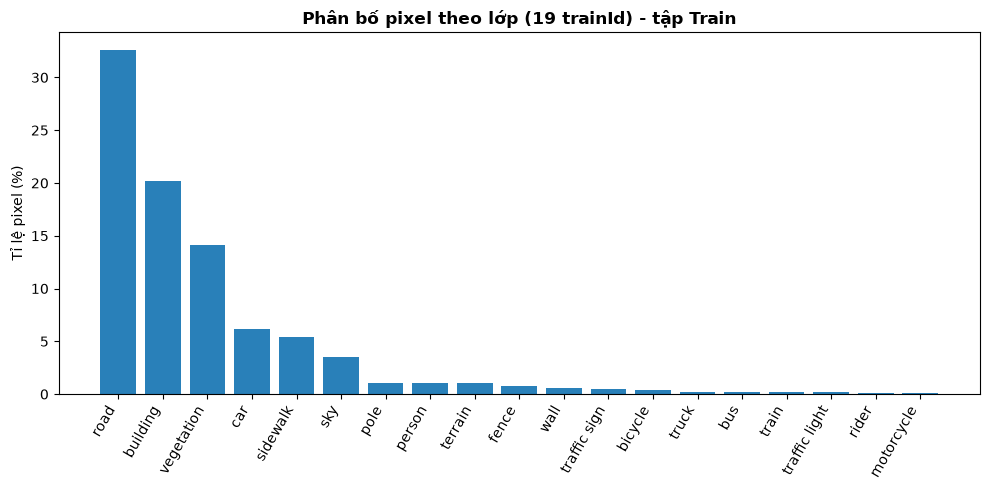

,trainId,class_name,pixel_count,ratio (%)
0,0,road,2036416525,32.639969
1,2,building,1260636120,20.205652
2,8,vegetation,879783988,14.101301
3,255,ignore,715747311,11.472098
4,13,car,386328286,6.192124
5,1,sidewalk,336090793,5.386910
6,10,sky,221979646,3.557921
7,5,pole,67789506,1.086540
8,11,person,67326424,1.079117
9,9,terrain,63949536,1.024992


In [17]:
# 3.2 Phân bố số lượng pixel theo lớp (trainId) trên tập train
pixel_counts = Counter()
for _, mask_path in split_pairs["train"]:
    label_id = np.array(Image.open(mask_path))
    train_id_mask = id_to_trainid_map(label_id)
    values, counts = np.unique(train_id_mask, return_counts=True)
    pixel_counts.update(dict(zip(values.tolist(), counts.tolist())))

class_pixel_df = pd.DataFrame([
    {"trainId": tid, "class_name": TRAINID_TO_NAME.get(tid, "ignore"), "pixel_count": cnt}
    for tid, cnt in sorted(pixel_counts.items())
])
class_pixel_df["ratio (%)"] = 100 * class_pixel_df["pixel_count"] / class_pixel_df["pixel_count"].sum()

fg = class_pixel_df[class_pixel_df["trainId"] != IGNORE_INDEX].sort_values("pixel_count", ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(fg["class_name"], fg["ratio (%)"], color="#2980b9")
plt.xticks(rotation=60, ha="right")
plt.ylabel("Tỉ lệ pixel (%)")
plt.title("Phân bố pixel theo lớp (19 trainId) - tập Train", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "class_pixel_distribution.png"), dpi=150)
plt.show()

display(class_pixel_df.sort_values("pixel_count", ascending=False).reset_index(drop=True))

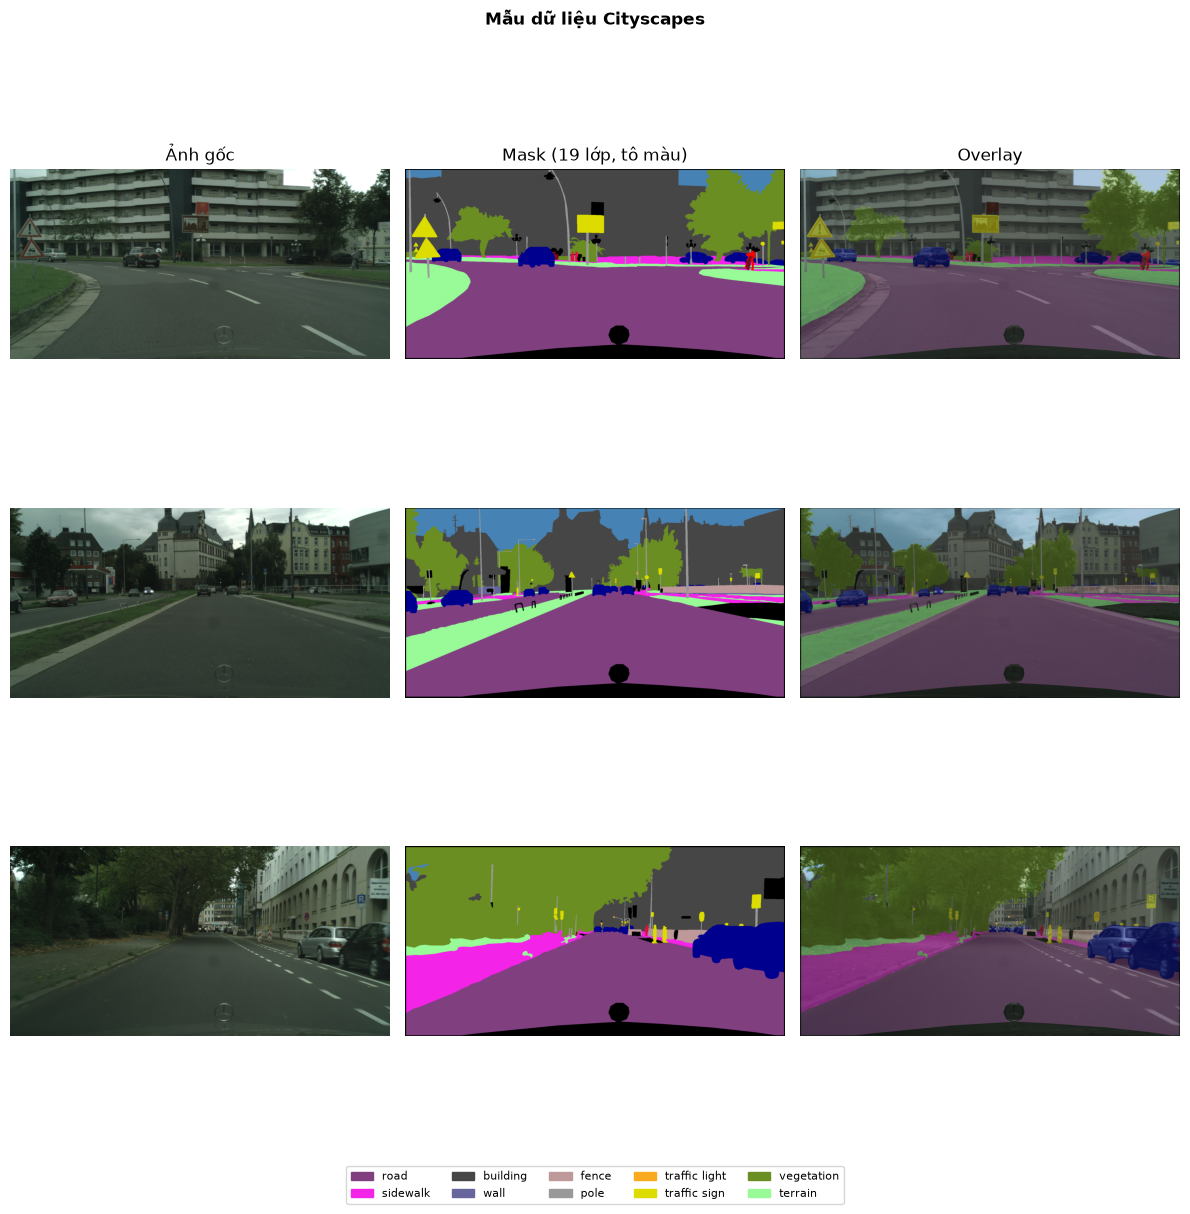

In [18]:
# 3.3 Trực quan hóa một vài mẫu: Ảnh gốc | Mask màu | Ảnh phủ mask (overlay)
n_show = min(3, len(split_pairs["train"]))
fig, axes = plt.subplots(n_show, 3, figsize=(12, 4 * n_show))
if n_show == 1:
    axes = axes[None, :]

for row, (img_path, mask_path) in enumerate(split_pairs["train"][:n_show]):
    image = np.array(Image.open(img_path).convert("RGB"))
    label_id = np.array(Image.open(mask_path))
    train_id_mask = id_to_trainid_map(label_id)
    color_mask = trainid_to_color_map(train_id_mask)
    overlay = (0.55 * image + 0.45 * color_mask).astype(np.uint8)

    axes[row, 0].imshow(image)
    axes[row, 0].set_title("Ảnh gốc" if row == 0 else "")
    axes[row, 1].imshow(color_mask)
    axes[row, 1].set_title("Mask (19 lớp, tô màu)" if row == 0 else "")
    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title("Overlay" if row == 0 else "")
    for ax in axes[row]:
        ax.axis("off")

legend_handles = [Patch(color=np.array(c) / 255.0, label=n) for n, c in
                  zip(list(TRAINID_TO_NAME.values())[:10], list(TRAINID_TO_COLOR.values())[:10])]
fig.legend(handles=legend_handles, loc="lower center", ncol=5, fontsize=8, bbox_to_anchor=(0.5, -0.02))

plt.suptitle(
    f"Mẫu dữ liệu Cityscapes{' (SYNTHETIC - chưa có dữ liệu thật)' if USING_SYNTHETIC_DATA else ''}",
    fontweight="bold"
)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "sample_batch_cityscapes.png"), dpi=150, bbox_inches="tight")
plt.show()

## 4. Dataset, DataLoader và Augmentation

Hiện thực `CityscapesSegmentation(Dataset)` tự viết (không phụ thuộc
`torchvision.datasets.Cityscapes` để kiểm soát rõ bước ánh xạ `id -> trainId`), áp dụng
augmentation **đồng bộ** trên cả ảnh và mask bằng `torchvision.transforms.v2`
(hỗ trợ transform chung cho ảnh + mask qua `tv_tensors.Mask`, đảm bảo phép biến đổi hình học
— crop, flip — được áp dụng giống hệt nhau trên cả hai).

- **Train:** `RandomResizedCrop` (quy mô nhỏ hơn ảnh gốc để tăng tốc huấn luyện ở A2.2),
  `RandomHorizontalFlip`, `ColorJitter` (chỉ áp dụng lên ảnh, không áp dụng lên mask),
  chuẩn hóa theo thống kê ImageNet (phù hợp khi dùng backbone pretrained ResNet/MiT).
- **Val/Test:** chỉ `Resize` + chuẩn hóa (không augmentation ngẫu nhiên).

In [19]:
from torchvision import tv_tensors

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
CROP_SIZE = (256, 512)  # (H, W) — thu nhỏ so với ảnh gốc 1024x2048 để huấn luyện nhanh hơn ở A2.2


class CityscapesSegmentation(Dataset):
    """Dataset phân đoạn ngữ nghĩa Cityscapes tự viết: đọc ảnh RGB + mask labelIds,
    ánh xạ sang 19 trainId, áp dụng augmentation đồng bộ ảnh/mask."""

    def __init__(self, pairs, transforms=None):
        self.pairs = pairs
        self.transforms = transforms

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]

        image = tv_tensors.Image(Image.open(img_path).convert("RGB"))
        label_id = np.array(Image.open(mask_path), dtype=np.int64)
        train_id = id_to_trainid_map(label_id).astype(np.int64)
        mask = tv_tensors.Mask(torch.from_numpy(train_id))

        if self.transforms is not None:
            image, mask = self.transforms(image, mask)

        return image, mask.long()


def get_transforms(split: str):
    if split == "train":
        return T.Compose([
            T.RandomResizedCrop(size=CROP_SIZE, scale=(0.5, 1.0), antialias=True),
            T.RandomHorizontalFlip(p=0.5),
            T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
            T.ToDtype({tv_tensors.Image: torch.float32, tv_tensors.Mask: torch.int64}, scale=True),
            T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ])
    return T.Compose([
        T.Resize(size=CROP_SIZE, antialias=True),
        T.ToDtype({tv_tensors.Image: torch.float32, tv_tensors.Mask: torch.int64}, scale=True),
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])


train_dataset = CityscapesSegmentation(split_pairs["train"], transforms=get_transforms("train"))
val_dataset = CityscapesSegmentation(split_pairs["val"], transforms=get_transforms("val"))
test_dataset = CityscapesSegmentation(split_pairs["test"], transforms=get_transforms("val"))

print(f"Train: {len(train_dataset):,} | Val: {len(val_dataset):,} | Test: {len(test_dataset):,}")

Train: 2,975 | Val: 500 | Test: 1,525


In [20]:
BATCH_SIZE = 4  # nhỏ vì ảnh phân đoạn nặng hơn nhiều so với ảnh phân loại ở E1/E2

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

images, masks = next(iter(train_loader))
print(f"Batch ảnh : {tuple(images.shape)} | dtype={images.dtype}")
print(f"Batch mask: {tuple(masks.shape)} | dtype={masks.dtype}")
print(f"Giá trị trainId trong batch: {sorted(torch.unique(masks).tolist())}")

Batch ảnh : (4, 3, 256, 512) | dtype=torch.float32
Batch mask: (4, 256, 512) | dtype=torch.int64
Giá trị trainId trong batch: [0, 1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 18, 255]


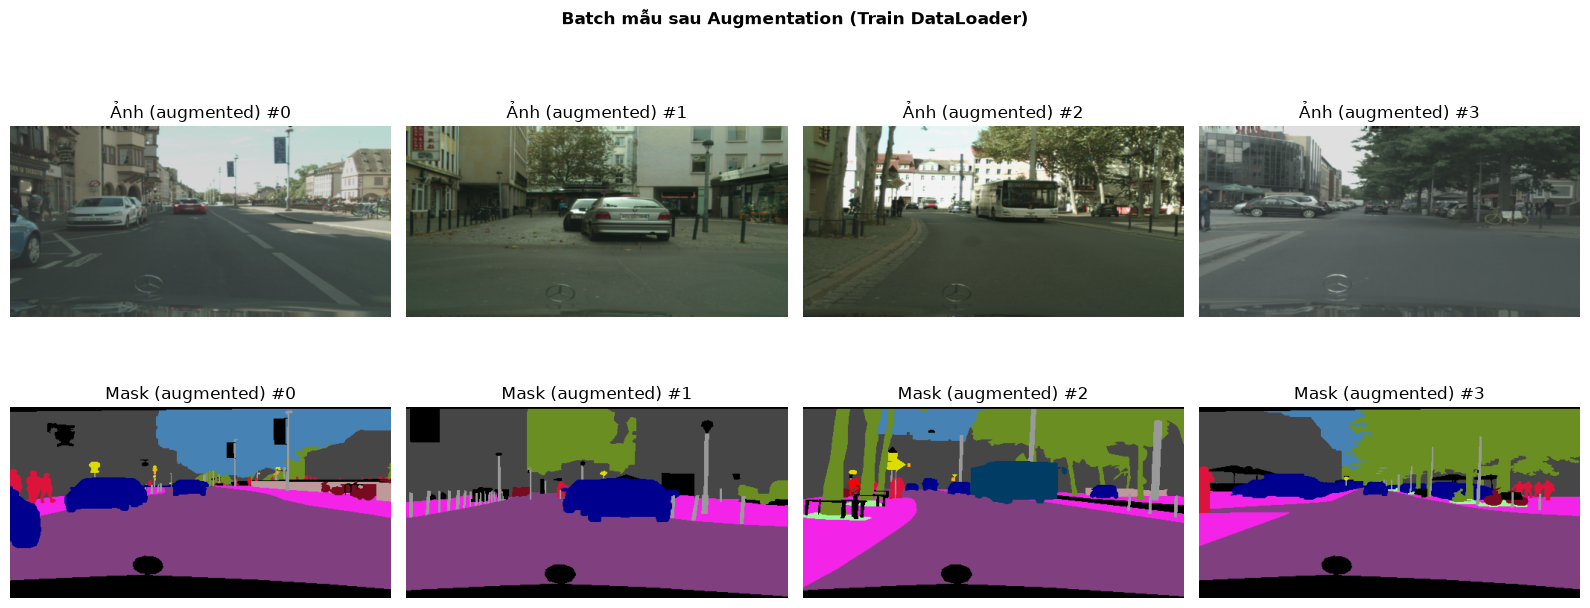

In [21]:
# Trực quan hóa một batch sau augmentation (giải chuẩn hóa ảnh để hiển thị đúng màu)
def denormalize(img_tensor: torch.Tensor) -> np.ndarray:
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    img = img_tensor.cpu() * std + mean
    return img.clamp(0, 1).permute(1, 2, 0).numpy()


n_show = min(4, images.size(0))
fig, axes = plt.subplots(2, n_show, figsize=(4 * n_show, 7))
for i in range(n_show):
    axes[0, i].imshow(denormalize(images[i]))
    axes[0, i].set_title(f"Ảnh (augmented) #{i}")
    axes[0, i].axis("off")

    mask_np = masks[i].numpy()
    axes[1, i].imshow(trainid_to_color_map(mask_np))
    axes[1, i].set_title(f"Mask (augmented) #{i}")
    axes[1, i].axis("off")

plt.suptitle("Batch mẫu sau Augmentation (Train DataLoader)", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "augmented_batch_sample.png"), dpi=150)
plt.show()